<a href="https://colab.research.google.com/github/192565074simats-code/MLA0201/blob/main/Experiment_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

========== TRAINING DATASET ==========


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,Target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,malignant
5,12.45,15.70,82.57,477.1,0.12780,0.17000,0.15780,0.08089,0.2087,0.07613,...,23.75,103.40,741.6,0.1791,0.5249,0.5355,0.1741,0.3985,0.12440,malignant
6,18.25,19.98,119.60,1040.0,0.09463,0.10900,0.11270,0.07400,0.1794,0.05742,...,27.66,153.20,1606.0,0.1442,0.2576,0.3784,0.1932,0.3063,0.08368,malignant
7,13.71,20.83,90.20,577.9,0.11890,0.16450,0.09366,0.05985,0.2196,0.07451,...,28.14,110.60,897.0,0.1654,0.3682,0.2678,0.1556,0.3196,0.11510,malignant
8,13.00,21.82,87.50,519.8,0.12730,0.19320,0.18590,0.09353,0.2350,0.07389,...,30.73,106.20,739.3,0.1703,0.5401,0.5390,0.2060,0.4378,0.10720,malignant
9,12.46,24.04,83.97,475.9,0.11860,0.23960,0.22730,0.08543,0.2030,0.08243,...,40.68,97.65,711.4,0.1853,1.0580,1.1050,0.2210,0.4366,0.20750,malignant



Total Samples: 569
Total Features: 30
Classes: ['malignant' 'benign']

Training Samples: 455
Testing Samples: 114

========== MODEL TRAINING COMPLETED ==========
Algorithm: Logistic Regression

========== PREDICTION RESULTS ==========


,Actual Class,Predicted Class
0,malignant,malignant
1,benign,benign
2,malignant,malignant
3,benign,benign
4,malignant,malignant
5,benign,benign
6,benign,benign
7,malignant,malignant
8,malignant,malignant
9,malignant,malignant



Testing Accuracy: 98.25 %

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114


========== CONFUSION MATRIX ==========
[[41  1]
 [ 1 71]]


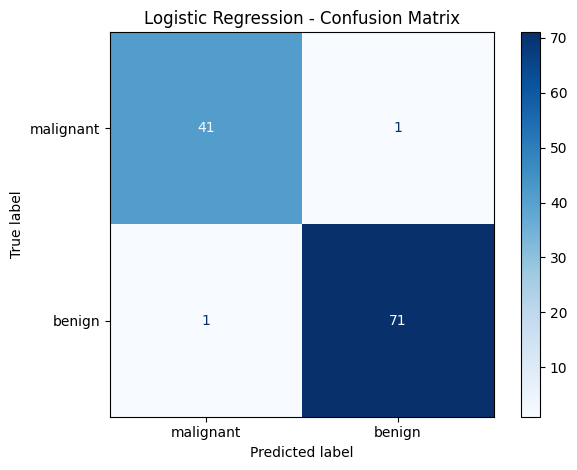

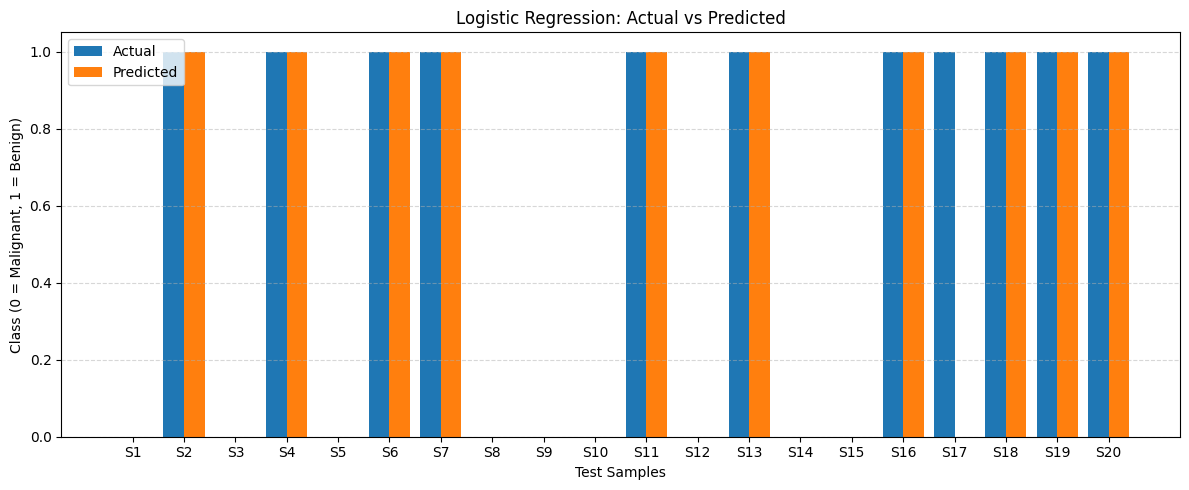

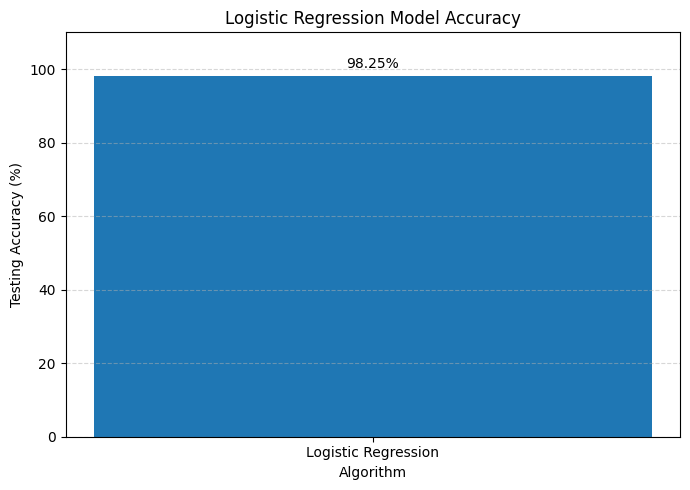

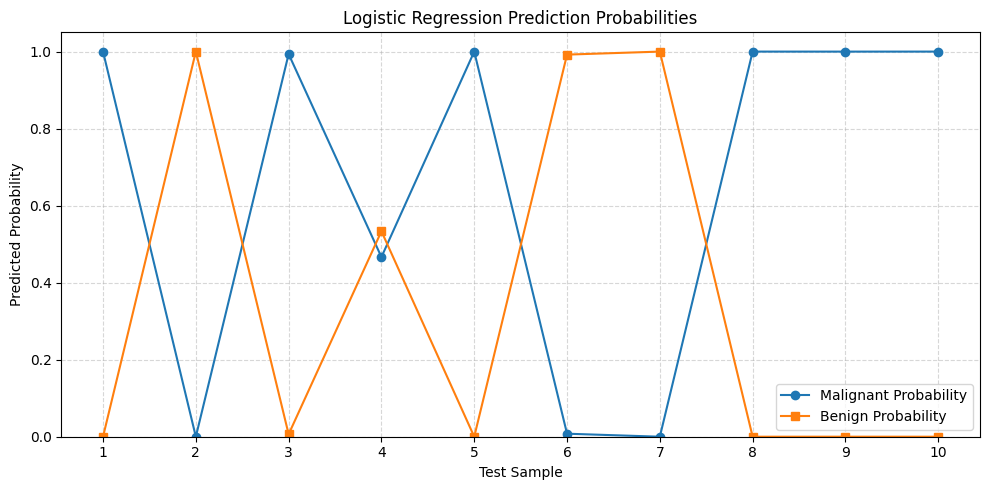


========== RESULT ==========
Logistic Regression Implemented Successfully.
Testing Accuracy: 98.25 %
Confusion Matrix Generated Successfully.


In [1]:
# EXPERIMENT 7: LOGISTIC REGRESSION USING PYTHON

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# STEP 1: LOAD TRAINING DATASET
dataset = load_breast_cancer()

X = dataset.data
y = dataset.target

df = pd.DataFrame(X, columns=dataset.feature_names)
df['Target'] = dataset.target_names[y]

print("========== TRAINING DATASET ==========")
display(df.head(10))

print("\nTotal Samples:", len(df))
print("Total Features:", X.shape[1])
print("Classes:", dataset.target_names)

# STEP 2: SPLIT DATASET
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))

# STEP 3: FEATURE SCALING
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# STEP 4: CREATE LOGISTIC REGRESSION MODEL
model = LogisticRegression(max_iter=5000)

# STEP 5: TRAIN THE MODEL
model.fit(X_train_scaled, y_train)

print("\n========== MODEL TRAINING COMPLETED ==========")
print("Algorithm: Logistic Regression")

# STEP 6: PREDICT TEST DATA
y_pred = model.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)

print("\n========== PREDICTION RESULTS ==========")

results = pd.DataFrame({
    'Actual Class': dataset.target_names[y_test],
    'Predicted Class': dataset.target_names[y_pred]
})

display(results.head(20))

print("\nTesting Accuracy:", round(accuracy * 100, 2), "%")

# STEP 7: CLASSIFICATION REPORT
print("\n========== CLASSIFICATION REPORT ==========")

print(classification_report(
    y_test,
    y_pred,
    target_names=dataset.target_names
))

# STEP 8: CONFUSION MATRIX
cm = confusion_matrix(y_test, y_pred)

print("\n========== CONFUSION MATRIX ==========")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=dataset.target_names
)

disp.plot(cmap='Blues', values_format='d')
plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()

# STEP 9: ACTUAL VS PREDICTED BAR GRAPH
sample_count = min(20, len(y_test))
sample_index = np.arange(sample_count)

plt.figure(figsize=(12, 5))

plt.bar(
    sample_index - 0.2,
    y_test[:sample_count],
    width=0.4,
    label='Actual'
)

plt.bar(
    sample_index + 0.2,
    y_pred[:sample_count],
    width=0.4,
    label='Predicted'
)

plt.title("Logistic Regression: Actual vs Predicted")
plt.xlabel("Test Samples")
plt.ylabel("Class (0 = Malignant, 1 = Benign)")

plt.xticks(
    sample_index,
    [f'S{i+1}' for i in sample_index]
)

plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# STEP 10: ACCURACY BAR GRAPH
plt.figure(figsize=(7, 5))

plt.bar(
    ['Logistic Regression'],
    [accuracy * 100]
)

plt.title("Logistic Regression Model Accuracy")
plt.xlabel("Algorithm")
plt.ylabel("Testing Accuracy (%)")
plt.ylim(0, 110)

plt.text(
    0,
    accuracy * 100 + 2,
    f'{accuracy * 100:.2f}%',
    ha='center'
)

plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# STEP 11: PREDICTION PROBABILITY GRAPH
probabilities = model.predict_proba(X_test_scaled[:10])

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(probabilities) + 1),
    probabilities[:, 0],
    marker='o',
    label='Malignant Probability'
)

plt.plot(
    range(1, len(probabilities) + 1),
    probabilities[:, 1],
    marker='s',
    label='Benign Probability'
)

plt.title("Logistic Regression Prediction Probabilities")
plt.xlabel("Test Sample")
plt.ylabel("Predicted Probability")
plt.ylim(0, 1.05)
plt.xticks(range(1, len(probabilities) + 1))
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# STEP 12: FINAL RESULT
print("\n========== RESULT ==========")
print("Logistic Regression Implemented Successfully.")
print("Testing Accuracy:", round(accuracy * 100, 2), "%")
print("Confusion Matrix Generated Successfully.")